<b><font size="6" color="#E8800A">04 · Preprocessing (Nico)</font></b><br>
<b><font size="4">Missing values, outliers, encoding and scaling, each chosen by a paired comparison</font></b>

**Owner:** Nico

**Question:** how should the clean data be prepared for the models, and which choice is backed by a measurement?

**Ground rules** (the course method of Weeks 3–5)
- **Look before changing anything:** every block starts from what the data show.
- **One block of decisions at a time,** in the course order: missing values → outliers → encoding and scaling. Each block starts from the recipe the previous one fixed.
- **Every learned step is fitted on the training rows of each fold only** (`FoldPreprocessor`), so validation rows never help compute a fill, a limit or an encoding.
- **Every option is compared with the current recipe fold by fold** (`paired_delta`) and read at **two standard errors**.
- **Every decision is recorded** in a `CleaningLog`, as a rule a later notebook can rebuild, not as fitted values.

**Not here:** deleting rows or columns (cleaning in `02`, feature selection in `05`), new features (`05`), model choice and tuning (`06`).

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>Setup</font>](#setup)
* [<font color='#E8800A'>1. How a choice is verified</font>](#method)
* [<font color='#E8800A'>2. Missing values</font>](#missing)
* [<font color='#E8800A'>3. Outliers</font>](#outliers)
* [<font color='#E8800A'>4. Encoding and scaling</font>](#encoding)
* [<font color='#E8800A'>5. The final recipe</font>](#final)
* [<font color='#E8800A'>6. The decision log</font>](#log)
* [<font color='#E8800A'>7. Summary</font>](#summary)

</div>

# <font color='#E8800A'>Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

__Step 1:__ Load the clean data and the validation scheme.

`%run` executes `validation_ludovico.ipynb`, which runs `cleaning_ludovico.ipynb` first (`%%capture` hides their output). It gives back:
- `train`, `test`: the clean data;
- `X`, `y`, `dates`: features, target and purchase dates of train;
- `schemes`, `models`: the time-CV splits and the V01 baseline pipelines;
- `evaluate`, `best_threshold`: fold scoring and F1 threshold search.

In [1]:
%%capture
%run ./validation_ludovico.ipynb

__Step 2:__ Import the course tools. Both modules sit in `src/` exactly as the course ships them, one module per job (Week 4):
- `preprocessing.py` applies a recipe. Its `FoldPreprocessor` turns a recipe (a dictionary of rules) into a transformer that is fitted inside each fold.
- `course_helpers.py` records decisions. Its `CleaningLog` writes each decision, its reason and its rule to a JSON file that a later notebook can read back.

In [2]:
import warnings

from scipy import stats
from sklearn.exceptions import ConvergenceWarning
from sklearn.neighbors import KNeighborsClassifier

from src.course_helpers import CleaningLog
from src.preprocessing import FoldPreprocessor
from src.paths import PROJECT_ROOT

LOG_PATH = PROJECT_ROOT / "docs" / "preprocessing_log.json"

__Step 3:__ Choose the folds. The team uses the three yearly folds of `validation_ludovico`. The six half-year folds measured in `validation_folds_nico` are ready as an alternative: switching is one line, and every number below follows.

In [3]:
SCHEME_STARTS = {
    "3 yearly": TIME_CV_STARTS,
    "6 half-yearly from 2022": [str(d.date()) for d in pd.date_range("2022-01-01", "2024-07-01", freq="6MS")],
}
SCHEME = "3 yearly"   # or "6 half-yearly from 2022"

splits = list(time_splits(dates, SCHEME_STARTS[SCHEME]))
NUMERIC = X.select_dtypes("number").columns.tolist()
CATEGORICAL = X.select_dtypes(["string", "object"]).columns.tolist()

print(f"{SCHEME}: {len(splits)} folds, validation rows {[len(va) for _, va in splits]}")
print(f"X: {len(X):,} rows, {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical columns")

3 yearly: 3 folds, validation rows [628, 767, 835]
X: 6,469 rows, 28 numeric + 6 categorical columns


# <font color='#E8800A'>1. How a choice is verified</font> <a class="anchor" id="method"></a>
[Back to TOC](#toc)

**The problem.** A recipe gets one score per fold, and the folds differ a lot: some periods are harder to predict whatever the recipe. The difference between two recipes is usually much smaller than the difference between two periods, so comparing two averages mixes the two effects.

**The course solution: a paired comparison** (Week 4, `paired_delta`)
1. Score both recipes on the **same folds**, so a hard period penalises both.
2. Take the difference **fold by fold**: the difficulty of each period cancels, the effect of the recipe remains.
3. The **standard error of the mean (SEM)** of those differences, their standard deviation divided by √(number of folds), says how much the mean difference would move with other folds.
4. **Verdict at two SEM:** "better" or "worse" when |mean difference| > 2 × SEM, otherwise "inside the noise". About 95% of chance fluctuations stay within two standard errors.

**The metric for comparisons: ROC AUC.** It measures how well the model ranks repeat buyers above the others, at any threshold. F1, the Kaggle metric, depends on the threshold, and `validation_folds_nico` showed that F1 at a fixed threshold misses real differences. F1 is used once, for the final estimate next to Kaggle (§5).

**The model that judges the recipe:** the logistic regression of `validation_ludovico`. A penalised linear model reacts to how its inputs are filled, transformed, encoded and scaled. A tree would hide most of these choices, because it only reads thresholds. The other families are checked at the end (§5).

__Step 4:__ `paired_delta` as in Week 4, with one change: the course compares an error (MAE, lower is better), here the score is ROC AUC (higher is better), so the sign of "better" is flipped. The ratio |dAUC| / SEM is returned too: the verdict is "better" or "worse" exactly when it is above 2, and rounded numbers can hide how close a result is to the line.

In [4]:
def paired_delta(scores, reference):
    """Week 4 paired_delta for ROC AUC: mean fold-by-fold difference, its SEM, folds won and verdict."""
    delta = np.asarray(scores) - np.asarray(reference)
    if not delta.any():
        return {"dAUC": 0.0, "SEM": 0.0, "ratio": 0.0, "better": f"0/{len(delta)}",
                "verdict": "identical on every split"}
    sem = delta.std(ddof=1) / np.sqrt(len(delta))      # ddof=1: sample standard deviation
    verdict = ("inside the noise" if abs(delta.mean()) <= 2 * sem
               else "better" if delta.mean() > 0 else "worse")
    return {"dAUC": delta.mean(), "SEM": sem, "ratio": abs(delta.mean()) / sem,
            "better": f"{int((delta > 0).sum())}/{len(delta)}", "verdict": verdict}

__Step 5:__ The bookkeeping, as in Week 4. `report` scores a recipe, files it on a shared `board` and prints its verdict against another entry. `show` prints entries side by side. `choose` applies the decision rule declared below.

In [5]:
board, oofs, results = {}, {}, {}   # per-fold scores, out-of-fold probabilities, summary rows


def cv_run(recipe, frame=X, model=None):
    """Score recipe + model on the folds; every step is refitted on each training fold."""
    model = LogisticRegression(max_iter=3000) if model is None else model
    pipeline = make_pipeline(FoldPreprocessor(recipe, selection=None), model)
    return evaluate(pipeline, splits, frame, y)


def report(name, recipe, frame=X, against=None, model=None):
    """Score a recipe, file it on the board and print its verdict against another board entry."""
    scores, oof = cv_run(recipe, frame, model)
    board[name], oofs[name] = scores, oof
    row = {"ROC AUC": scores["ROC AUC"].mean(), "per fold": scores["ROC AUC"].round(4).tolist()}
    line = f"{name}: ROC AUC {row['ROC AUC']:.4f} {row['per fold']}"
    if against is not None:
        row.update(paired_delta(scores["ROC AUC"], board[against]["ROC AUC"]), against=against)
        line += (f"\n    vs {against}: dAUC {row['dAUC']:+.4f} +- {row['SEM']:.4f}"
                 f" (ratio {row['ratio']:.1f}), better on {row['better']} folds -> {row['verdict'].upper()}")
    results[name] = row
    print(line)


def show(names):
    """Summary rows of these board entries, side by side."""
    return pd.DataFrame({n: results[n] for n in names}).T.style.format(
        {"ROC AUC": "{:.4f}", "dAUC": "{:+.4f}", "SEM": "{:.4f}", "ratio": "{:.1f}"}, na_rep="")


def choose(candidates, current):
    """Decision rule: the best mean among candidates judged 'better' than `current`; `current` if none."""
    better = [n for n in candidates if results[n].get("verdict") == "better" and results[n].get("against") == current]
    if not better:
        print(f"KEPT: {current} (no candidate is better beyond 2 SEM)")
        return current
    best = max(better, key=lambda n: results[n]["ROC AUC"])
    print(f"ADOPTED: {best} (better beyond 2 SEM: {better})")
    return best

<div class="alert alert-block alert-info">

**Decision rule, declared before any result.** A candidate replaces the current recipe only if its verdict is **better** (more than 2 SEM). Among several, the one with the highest mean ROC AUC wins. A tie, or a gain inside the noise, keeps the current, simpler recipe.

With 3 folds the SEM rests on 3 differences, so about one tie in six is still called a winner (`validation_folds_nico`). The ratio and the folds won are printed beside every verdict, so a borderline result can be read for what it is.

</div>

__Step 6:__ The recipe format. `FoldPreprocessor` reads a dictionary with fixed keys, the same the course's log carries. Each block below changes **one** key and keeps the others.

| Key | Meaning | Starting value | Decided in |
|---|---|---|---|
| `numeric`, `categorical` | which columns enter, and as what | 28 numeric + 6 categorical | |
| `dropped` | columns kept out of the model | identifier, raw date, decoy column | `05_features` |
| `fill` | how gaps are filled | median / mode (V01 baseline) | §2 |
| `log1p`, `outliers` | outlier treatment | none, keep | §3 |
| `encoding`, `drop` | categorical encoding | one-hot, drop first | §4 |
| `scaler` | scaling | standard | §4 |
| `strategy` | feature selection | None | `05_features` |

In [6]:
START = {
    "numeric": NUMERIC, "categorical": CATEGORICAL,
    "dropped": ["customer_id", "purchase_date", "random_noise"],
    "fill": {"numeric": "median", "categorical": "mode"},
    "log1p": [], "outliers": "keep",
    "encoding": "one-hot", "drop": "first", "scaler": "standard",
    "strategy": None,
}

__Step 7:__ Sanity check. The starting recipe applied through `FoldPreprocessor` should score like the V01 pipeline of `validation_ludovico`, which is written with a `ColumnTransformer`. Small differences are expected: V01 groups levels with fewer than 20 rows, while the course one-hot drops the first level and keeps every other one.

The **V01 pipeline** is filed on the board as the reference of the whole notebook.

In [7]:
V01 = "V01 baseline"
scores, oof = evaluate(models["logistic regression"], splits, X, y)
board[V01], oofs[V01] = scores, oof
results[V01] = {"ROC AUC": scores["ROC AUC"].mean(), "per fold": scores["ROC AUC"].round(4).tolist()}
print(f"{V01}: ROC AUC {results[V01]['ROC AUC']:.4f} {results[V01]['per fold']}")

# Expected messages here: unseen categories and slow convergence. Both are explained in §4.2 and §4.3.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    report("start (course format)", START, against=V01)

V01 baseline: ROC AUC 0.7781 [0.7763, 0.7843, 0.7736]
start (course format): ROC AUC 0.7800 [0.7816, 0.7876, 0.7706]
    vs V01 baseline: dAUC +0.0019 +- 0.0025 (ratio 0.7), better on 2/3 folds -> INSIDE THE NOISE


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ the starting recipe should be inside the noise of the V01 pipeline (ratio well below 2): if so, every later comparison starts from the same place as the V01 submission.

# <font color='#E8800A'>2. Missing values</font> <a class="anchor" id="missing"></a>
[Back to TOC](#toc)

> *"A missing value is unknown, not wrong."* (Week 3)

The **wrong** values are already handled: `cleaning_ludovico` turned impossible values into NaN and rebuilt the ones exact identities give back. The NaN left are **unknown**. scikit-learn models stop with an error when they meet a NaN, so every gap must be filled, and the filled value is invented. The question is which invented value does the least harm and keeps the most information.

| Kind of missing value | Meaning | What matters when filling it |
|---|---|---|
| **Scattered** | the value exists but was not recorded, by chance | invent a plausible value |
| **Structural** | the value **cannot exist** | any value is fake; what matters is that the model can tell |
| **Informative** | the **fact** that it is missing says something about the target | do not throw that fact away |

From here on, the warnings about unseen categories and convergence are silenced: §4 explains both.

In [8]:
warnings.filterwarnings("ignore", category=UserWarning)        # one-hot: unseen categories (see §4.2)
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # unscaled solver (see §4.3)

## <font color='#E8800A'>2.1 What is missing, and why</font>

__Step 8:__ Count the gaps per column, in train and in test.

In [9]:
X_test = test[X.columns]
gaps = pd.DataFrame({"train": X.isna().sum(), "train %": (100 * X.isna().mean()).round(1),
                     "test": X_test.isna().sum()})
gaps = gaps[gaps["train"] > 0].sort_values("train", ascending=False)
print(f"rows with at least one gap: train {X.isna().any(axis=1).sum():,} of {len(X):,},"
      f" test {X_test.isna().any(axis=1).sum():,} of {len(X_test):,}")
gaps

rows with at least one gap: train 2,157 of 6,469, test 217 of 986


,train,train %,test
prior_std_gap_days,1413,21.8,69
prior_mean_gap_days,1056,16.3,46
prior_std_purchase_value,1048,16.2,46
prior_max_purchase_value,645,10.0,28
days_since_previous_purchase,611,9.4,22
prior_mean_purchase_value,603,9.3,22
prior_min_purchase_value,603,9.3,22
transport_method,196,3.0,30
warehouse,195,3.0,30
payment_type,195,3.0,30


__Step 9:__ The history columns. A gap between purchases needs at least two prior purchases, and a spread of gaps needs at least three. Count the gaps by number of prior purchases, beside the repeat rate of each group.

In [10]:
HISTORY = ["prior_mean_gap_days", "prior_std_gap_days", "prior_std_purchase_value",
           "prior_max_purchase_value", "days_since_previous_purchase"]
depth = X["prior_purchase_count"].clip(upper=3).rename("prior purchases (3 = 3+)")
X[HISTORY].isna().groupby(depth).sum().assign(rows=depth.value_counts().sort_index(),
                                               repeat_rate=y.groupby(depth).mean().round(3))

,prior_mean_gap_days,prior_std_gap_days,prior_std_purchase_value,prior_max_purchase_value,days_since_previous_purchase,rows,repeat_rate
prior purchases (3 = 3+),,,,,,,
0.0,603,603,603,603,603,603,0.333
1.0,445,445,445,0,0,445,0.373
2.0,2,365,0,1,2,365,0.400
3.0,6,0,0,41,6,5056,0.615


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ which history columns are empty for 0, 1 and 2 prior purchases (structural gaps), how many gaps remain for 3+ purchases (scattered), and how the repeat rate changes with the number of prior purchases (informative). Note that `prior_purchase_count` itself has no gaps.

__Step 10:__ The other gaps. Does missingness move the target, and do the gaps fall on the same rows?

In [11]:
SCATTERED = ["payment_type", "salesperson", "transport_method", "warehouse", "spend_365d"]
missingness = pd.DataFrame({col: {"repeat rate if missing": y[X[col].isna()].mean(),
                                  "repeat rate if present": y[X[col].notna()].mean(),
                                  "rows missing": X[col].isna().sum()} for col in SCATTERED}).T
per_row = X[SCATTERED[:4]].isna().sum(axis=1)
print(f"rows with a gap in one of the 4 categoricals: {(per_row >= 1).sum()}, in two or more: {(per_row >= 2).sum()}")
missingness.round(3)

rows with a gap in one of the 4 categoricals: 749, in two or more: 31


,repeat rate if missing,repeat rate if present,rows missing
payment_type,0.564,0.560,195.0
salesperson,0.598,0.559,194.0
transport_method,0.551,0.560,196.0
warehouse,0.636,0.557,195.0
spend_365d,0.647,0.558,156.0


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ whether the repeat rate differs between missing and present rows (informative or not), and whether gaps fall on different rows (scattered) or together.

## <font color='#E8800A'>2.2 The fill plans</font>

**Two rules from Week 3**
1. **A fill is fitted on the training rows and applied to both halves.** A median taken over the whole file would be partly taken from the rows the model is scored on: that is leakage. `FoldPreprocessor` refits the fill inside every fold.
2. **KNN and iterative imputation work on standardised columns**, then return their fills in the original units. KNN finds neighbours by distance, so without standardising, a column in tens of thousands (`prior_total_spend`) would choose the neighbours alone.

| Fill for numeric gaps | Becomes | Assumes |
|---|---|---|
| `median` | the training median | the typical value is a fair guess; unmoved by extreme values |
| `mean` | the training mean | the same, but the mean is pulled by long tails |
| `zero` | 0 | "missing" means "none": true for some columns, absurd for others |
| `KNN` (k=5) | mean of the 5 most similar training rows | similar customers on the other columns are similar on this one |
| `iterative` | each column predicted from the others, repeated | the same, through linear relations |

| Fill for categorical gaps | Becomes | Assumes |
|---|---|---|
| `own level` | a new level, `(missing)` | nothing is guessed: the model learns what "missing" is worth |
| `mode` | the most frequent training level | the most common case is the best guess |
| `proportional` | a level drawn at random in its training shares | keeps the mix of levels, but adds random noise |

**The plans** are the nine of Week 3, named *numeric / categorical*, with **median / own level** as the reference, as in the course. Two coincide with the reference on our data and are not scored:
- **skew-aware / own level** (median on skewed columns, mean on the others): the cell below shows how many columns are skewed.
- **median / missing left to encode:** the encoder then treats a NaN as a level of its own, which is exactly *own level*.

**median / training mode** is the plan of the V01 submission.

In [12]:
skewed = X[NUMERIC].skew() > 1
print(f"numeric columns with skew > 1: {skewed.sum()} of {len(NUMERIC)}; the others: {skewed[~skewed].index.tolist()}")

FILL_PLANS = {
    "median / own level": {"numeric": "median", "categorical": "own level"},   # course reference
    "mean / own level": {"numeric": "mean", "categorical": "own level"},
    "zero / own level": {"numeric": "zero", "categorical": "own level"},
    "median / training mode": {"numeric": "median", "categorical": "mode"},    # V01 submission
    "median / proportional": {"numeric": "median", "categorical": "proportional", "random_state": RANDOM_STATE},
    "KNN (k=5) / own level": {"numeric": "KNN", "n_neighbors": 5, "standardised": True, "categorical": "own level"},
    "iterative / own level": {"numeric": "iterative", "standardised": True, "random_state": RANDOM_STATE,
                              "categorical": "own level"},
}
FILL_REFERENCE = "median / own level"

numeric columns with skew > 1: 27 of 28; the others: ['customer_tenure_days']


## <font color='#E8800A'>2.3 The board</font>

__Step 11:__ Score the seven plans on the same folds, each against the reference. Only the `fill` key changes.

In [13]:
fill_names = [f"fill · {name}" for name in FILL_PLANS]
reference = f"fill · {FILL_REFERENCE}"
report(reference, {**START, "fill": FILL_PLANS[FILL_REFERENCE]})
for name in FILL_PLANS:
    if name != FILL_REFERENCE:
        report(f"fill · {name}", {**START, "fill": FILL_PLANS[name]}, against=reference)

fill · median / own level: ROC AUC 0.7810 [0.7842, 0.7859, 0.773]
fill · mean / own level: ROC AUC 0.7815 [0.7845, 0.787, 0.773]
    vs fill · median / own level: dAUC +0.0005 +- 0.0003 (ratio 1.6), better on 3/3 folds -> INSIDE THE NOISE
fill · zero / own level: ROC AUC 0.7819 [0.7849, 0.7866, 0.7741]
    vs fill · median / own level: dAUC +0.0008 +- 0.0002 (ratio 5.1), better on 3/3 folds -> BETTER
fill · median / training mode: ROC AUC 0.7800 [0.7816, 0.7876, 0.7706]
    vs fill · median / own level: dAUC -0.0011 +- 0.0014 (ratio 0.8), better on 1/3 folds -> INSIDE THE NOISE
fill · median / proportional: ROC AUC 0.7817 [0.7847, 0.7891, 0.7713]
    vs fill · median / own level: dAUC +0.0006 +- 0.0014 (ratio 0.5), better on 2/3 folds -> INSIDE THE NOISE
fill · KNN (k=5) / own level: ROC AUC 0.7824 [0.7852, 0.7888, 0.7733]
    vs fill · median / own level: dAUC +0.0014 +- 0.0008 (ratio 1.8), better on 3/3 folds -> INSIDE THE NOISE
fill · iterative / own level: ROC AUC 0.7820 [0.7852, 0

In [14]:
show(fill_names)

,ROC AUC,per fold,dAUC,SEM,ratio,better,verdict,against
fill · median / own level,0.7810,"[0.7842, 0.7859, 0.773]",,,,,,
fill · mean / own level,0.7815,"[0.7845, 0.787, 0.773]",+0.0005,0.0003,1.6,3/3,inside the noise,fill · median / own level
fill · zero / own level,0.7819,"[0.7849, 0.7866, 0.7741]",+0.0008,0.0002,5.1,3/3,better,fill · median / own level
fill · median / training mode,0.7800,"[0.7816, 0.7876, 0.7706]",-0.0011,0.0014,0.8,1/3,inside the noise,fill · median / own level
fill · median / proportional,0.7817,"[0.7847, 0.7891, 0.7713]",+0.0006,0.0014,0.5,2/3,inside the noise,fill · median / own level
fill · KNN (k=5) / own level,0.7824,"[0.7852, 0.7888, 0.7733]",+0.0014,0.0008,1.8,3/3,inside the noise,fill · median / own level
fill · iterative / own level,0.7820,"[0.7852, 0.7876, 0.7733]",+0.0010,0.0004,2.5,3/3,better,fill · median / own level


__Step 12:__ The board as a picture: each candidate's difference from the reference, fold by fold (dots), and its mean with ± 2 SEM (bar). A bar that does not touch 0 is a real difference.

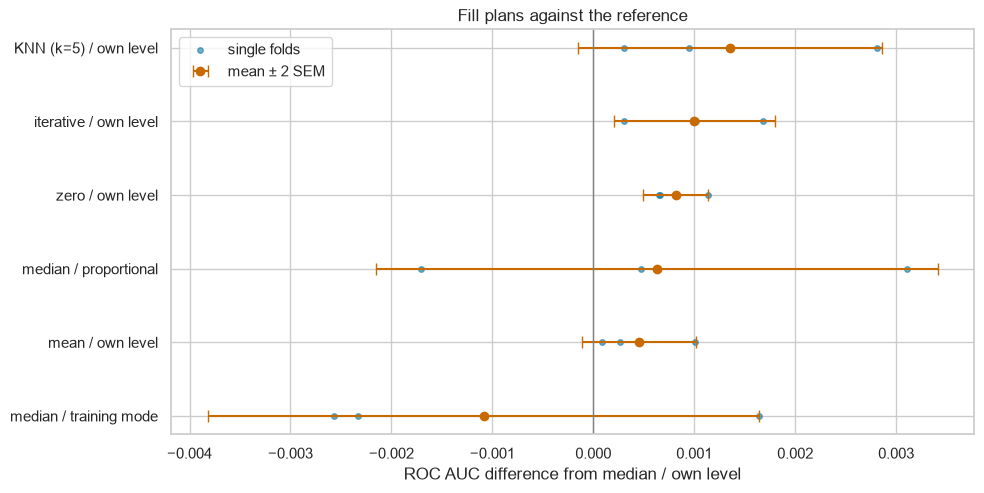

In [15]:
def plot_deltas(names, reference, title):
    """Fold-by-fold differences from `reference` (dots) and mean +- 2 SEM (bars)."""
    names = sorted(names, key=lambda n: results[n]["dAUC"])
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(names) + 1.5))
    for i, name in enumerate(names):
        delta = board[name]["ROC AUC"].to_numpy() - board[reference]["ROC AUC"].to_numpy()
        ax.scatter(delta, [i] * len(delta), color=PLOT_BLUE, s=16, alpha=0.6,
                   label="single folds" if i == 0 else None)
        ax.errorbar(results[name]["dAUC"], i, xerr=2 * results[name]["SEM"], fmt="o",
                    color=PLOT_ORANGE, capsize=4, label="mean ± 2 SEM" if i == 0 else None)
    ax.axvline(0, color="grey", lw=1)
    ax.set_yticks(range(len(names)), [n.split(" · ", 1)[1] for n in names])
    ax.set(xlabel=f"ROC AUC difference from {reference.split(' · ', 1)[1]}", title=title)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


plot_deltas([n for n in fill_names if n != reference], reference, "Fill plans against the reference")

In [16]:
fill_choice = choose(fill_names, reference)

ADOPTED: fill · iterative / own level (better beyond 2 SEM: ['fill · zero / own level', 'fill · iterative / own level'])


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ which plans are better beyond 2 SEM (ratio > 2), which one the rule adopts, how close the others are to the line (e.g. a large mean with a ratio below 2), where the V01 plan (median / training mode) sits, and above all **how large** the differences are: if every plan is within about ±0.002, the fill is not a lever for the score.

## <font color='#E8800A'>2.4 Structural gaps as information</font>

A fill gives a first purchase the gap of a typical customer: a fake value that looks like a regular buyer. The model also sees `prior_purchase_count`, so it may already know the value is fake. Whether it does is measured, not assumed.

`FoldPreprocessor` has no missing-indicator option, so the information is added the way Week 4 adds `km_per_year`: as **constructed columns**, defined by a formula and judged by a paired delta. The formula reads only the row itself, so it fits nothing and cannot leak.

__Step 13:__ Three 0/1 flags for the history depth that decides which columns are structurally empty, added to the plan chosen in §2.3.

In [17]:
FLAGS = ["no_prior_purchase", "one_prior_purchase", "two_prior_purchases"]


def add_history_flags(frame):
    """0/1 flags for 0, 1 and 2 prior purchases: the depths that leave history columns empty."""
    count = frame["prior_purchase_count"]
    return frame.assign(no_prior_purchase=(count == 0).astype(int),
                        one_prior_purchase=(count == 1).astype(int),
                        two_prior_purchases=(count == 2).astype(int))


fill_plan = FILL_PLANS[fill_choice.split(" · ", 1)[1]]
flags_name = "fill · chosen plan + history flags"
report(flags_name, {**START, "fill": fill_plan, "numeric": NUMERIC + FLAGS},
       frame=add_history_flags(X), against=fill_choice)
flags_added = results[flags_name]["verdict"] == "better"

fill · chosen plan + history flags: ROC AUC 0.7819 [0.7866, 0.7863, 0.7727]
    vs fill · iterative / own level: dAUC -0.0002 +- 0.0008 (ratio 0.2), better on 1/3 folds -> INSIDE THE NOISE


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ whether the flags are better beyond 2 SEM. If not, the information is already carried by `prior_purchase_count` and the flags are not added (`05_features` may test them again with tree models).

## <font color='#E8800A'>2.5 Decision</font>

__Step 14:__ Fix the fill in the recipe.

In [18]:
RECIPE = {**START, "fill": fill_plan}
FRAME = X
if flags_added:
    RECIPE["numeric"] = NUMERIC + FLAGS
    FRAME = add_history_flags(X)

current = "after §2 · missing values"
report(current, RECIPE, FRAME, against=V01)
print(f"\nfill: {RECIPE['fill']} | history flags added: {flags_added}")

after §2 · missing values: ROC AUC 0.7820 [0.7852, 0.7876, 0.7733]
    vs V01 baseline: dAUC +0.0039 +- 0.0027 (ratio 1.5), better on 2/3 folds -> INSIDE THE NOISE

fill: {'numeric': 'iterative', 'standardised': True, 'random_state': 42, 'categorical': 'own level'} | history flags added: False


# <font color='#E8800A'>3. Outliers</font> <a class="anchor" id="outliers"></a>
[Back to TOC](#toc)

An outlier is a value far from the others in its column. Far is not the same as wrong (Week 3, *"An outlier is not always a defect"*):

| Situation | Example | What is done |
|---|---|---|
| **Error** | −4 days, a spend of 10⁹ | fixed or set to NaN: the job of **cleaning**, already done |
| **Extreme but real** | a wholesaler who spent 250,000 € | **kept**: a real customer, often the most important |
| **Long tail** | most invoices under 1,000 €, a few far above | the **shape** of the column is changed, no row is removed |

**The course tools**
- **The 1.5 × IQR rule screens, it never decides.** IQR = Q3 − Q1; a value below Q1 − 1.5·IQR or above Q3 + 1.5·IQR is flagged. It raises the question "who are these rows?", answered by looking at them.
- **`log1p`** computes log(1 + x): it compresses a long right tail, keeps the order of the values and deletes nothing. It fits nothing, so it cannot leak. Recipe key: `log1p`.
- **Winsorize 1/99** caps every value at the 1st and 99th percentiles of the training rows of the fold. Recipe key: `outliers: "winsorize 1/99"`. Deleting rows is not an option of `FoldPreprocessor`: a transformer cannot remove training rows.
- **A transform is chosen per column, by a paired delta** (Week 4: `log1p` on `km_per_year` gave back its whole gain). So `log1p` is scored group by group, not only on everything at once.

## <font color='#E8800A'>3.1 Screening</font>

__Step 15:__ Apply the IQR rule to every numeric column, and compare the flagged rows with the others.

In [19]:
q1, q3 = X[NUMERIC].quantile(0.25), X[NUMERIC].quantile(0.75)
iqr = q3 - q1
outside = (X[NUMERIC] < q1 - 1.5 * iqr) | (X[NUMERIC] > q3 + 1.5 * iqr)
flagged = outside.any(axis=1)

print(f"rows flagged on at least one column: {flagged.sum():,} of {len(X):,} ({flagged.mean():.0%})")
print(f"repeat rate: flagged rows {y[flagged].mean():.3f}, other rows {y[~flagged].mean():.3f}")
print(f"columns with IQR = 0 (every non-typical value is 'outside'): {iqr[iqr == 0].index.tolist()}")

pd.DataFrame({"rows flagged": outside.sum(), "IQR": iqr, "% zeros": 100 * (X[NUMERIC] == 0).mean(),
              "skew": X[NUMERIC].skew(), "skew after log1p": np.log1p(X[NUMERIC].clip(lower=0)).skew()}
             ).sort_values("rows flagged", ascending=False).round(2)

rows flagged on at least one column: 4,259 of 6,469 (66%)
repeat rate: flagged rows 0.603, other rows 0.476
columns with IQR = 0 (every non-typical value is 'outside'): ['total_shipping', 'discount_global', 'invoice_count_current_purchase']


,rows flagged,IQR,% zeros,skew,skew after log1p
spend_30d,1060,338.24,67.12,5.50,0.88
total_shipping,1053,0.00,83.72,19.55,2.27
discount_line,822,92.28,37.73,5.92,0.24
purchase_count_180d,737,2.00,21.80,3.22,0.75
prior_min_purchase_value,671,147.16,0.00,5.90,0.04
spend_90d,661,1514.56,44.66,3.72,-0.02
prior_total_spend,642,20136.77,9.32,3.08,-1.60
total_to_pay,592,898.75,0.00,4.21,-0.48
total_net,587,748.99,0.00,4.15,-0.45
total_gross,584,860.96,0.00,4.31,-0.43


__Step 16:__ Look at who the most extreme rows are: the top 1% of three columns that describe how big and how loyal a customer is.

In [20]:
extremes = {}
for col in ["prior_total_spend", "total_net", "purchase_count_365d"]:
    top = X[col] >= X[col].quantile(0.99)
    extremes[col] = {"rows": int(top.sum()), "distinct customers": train.loc[top, "customer_id"].nunique(),
                     "repeat rate": round(y[top].mean(), 3), "column max": X[col].max()}
pd.DataFrame(extremes).T

,rows,distinct customers,repeat rate,column max
prior_total_spend,65.0,4.0,0.862,247865.10
total_net,65.0,23.0,0.692,18127.81
purchase_count_365d,84.0,1.0,0.988,60.00


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ the share of rows the IQR rule would delete, the repeat rate of flagged rows against the others, and who the top 1% are (few big customers, high repeat rate?). If the extremes are real, loyal customers, no row is deleted and only the shape of the columns is treated.

## <font color='#E8800A'>3.2 The board</font>

__Step 17:__ Score the treatments against the recipe of §2. The groups follow the column families of the EDA; inside each group, `log1p` goes only on the columns with skew > 1. The skew is read from the features alone, never from the target.

In [21]:
SKEWED = [c for c in NUMERIC if X[c].skew() > 1]
GROUPS = {
    "current amounts": ["total_to_pay", "total_gross", "total_net", "total_tax", "total_shipping",
                        "discount_global", "discount_line", "cost"],
    "history amounts": ["prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
                        "prior_min_purchase_value", "prior_max_purchase_value"],
    "rolling spend": [f"spend_{w}d" for w in (30, 90, 180, 365)],
    "counts": ["n_lines", "invoice_count_current_purchase", "prior_purchase_count"]
              + [f"purchase_count_{w}d" for w in (30, 90, 180, 365)],
    "day intervals": ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(c for c in NUMERIC if c != "customer_tenure_days"), \
    "every numeric column but customer_tenure_days (not skewed) belongs to one group"

TREATMENTS = {
    "winsorize 1/99": {"outliers": "winsorize 1/99"},
    "log1p · all skewed": {"log1p": SKEWED},
    "winsorize + log1p · all skewed": {"outliers": "winsorize 1/99", "log1p": SKEWED},
    **{f"log1p · {group}": {"log1p": [c for c in cols if c in SKEWED]} for group, cols in GROUPS.items()},
}

outlier_names = []
for treatment, change in TREATMENTS.items():
    name = f"outliers · {treatment}"
    report(name, {**RECIPE, **change}, FRAME, against=current)
    outlier_names.append(name)

outliers · winsorize 1/99: ROC AUC 0.7789 [0.7816, 0.7858, 0.7694]
    vs after §2 · missing values: dAUC -0.0031 +- 0.0006 (ratio 4.8), better on 0/3 folds -> WORSE
outliers · log1p · all skewed: ROC AUC 0.7819 [0.7818, 0.7875, 0.7764]
    vs after §2 · missing values: dAUC -0.0001 +- 0.0019 (ratio 0.1), better on 1/3 folds -> INSIDE THE NOISE
outliers · winsorize + log1p · all skewed: ROC AUC 0.7822 [0.7824, 0.7884, 0.7757]
    vs after §2 · missing values: dAUC +0.0001 +- 0.0016 (ratio 0.1), better on 2/3 folds -> INSIDE THE NOISE
outliers · log1p · current amounts: ROC AUC 0.7834 [0.7845, 0.7876, 0.778]
    vs after §2 · missing values: dAUC +0.0013 +- 0.0017 (ratio 0.8), better on 1/3 folds -> INSIDE THE NOISE
outliers · log1p · history amounts: ROC AUC 0.7802 [0.7819, 0.7876, 0.7711]
    vs after §2 · missing values: dAUC -0.0018 +- 0.0010 (ratio 1.9), better on 0/3 folds -> INSIDE THE NOISE
outliers · log1p · rolling spend: ROC AUC 0.7825 [0.7872, 0.7878, 0.7724]
    vs after §2

__Step 18:__ If more than one group passes on its own, their columns are combined and scored once more, as Week 4 combines what each family keeps.

In [22]:
passing = [n for n in outlier_names if "log1p · " in n and "all skewed" not in n
           and results[n]["verdict"] == "better"]
if len(passing) > 1:
    combined = sorted({c for n in passing for c in TREATMENTS[n.split(" · ", 1)[1]]["log1p"]})
    TREATMENTS["log1p · passing groups"] = {"log1p": combined}
    report("outliers · log1p · passing groups", {**RECIPE, "log1p": combined}, FRAME, against=current)
    outlier_names.append("outliers · log1p · passing groups")
print(f"groups better on their own: {passing}")
show(outlier_names)

groups better on their own: ['outliers · log1p · day intervals']


,ROC AUC,per fold,dAUC,SEM,ratio,better,verdict,against
outliers · winsorize 1/99,0.7789,"[0.7816, 0.7858, 0.7694]",-0.0031,0.0006,4.8,0/3,worse,after §2 · missing values
outliers · log1p · all skewed,0.7819,"[0.7818, 0.7875, 0.7764]",-0.0001,0.0019,0.1,1/3,inside the noise,after §2 · missing values
outliers · winsorize + log1p · all skewed,0.7822,"[0.7824, 0.7884, 0.7757]",+0.0001,0.0016,0.1,2/3,inside the noise,after §2 · missing values
outliers · log1p · current amounts,0.7834,"[0.7845, 0.7876, 0.778]",+0.0013,0.0017,0.8,1/3,inside the noise,after §2 · missing values
outliers · log1p · history amounts,0.7802,"[0.7819, 0.7876, 0.7711]",-0.0018,0.0010,1.9,0/3,inside the noise,after §2 · missing values
outliers · log1p · rolling spend,0.7825,"[0.7872, 0.7878, 0.7724]",+0.0004,0.0008,0.5,2/3,inside the noise,after §2 · missing values
outliers · log1p · counts,0.7772,"[0.7828, 0.7798, 0.7692]",-0.0048,0.0016,3.0,0/3,worse,after §2 · missing values
outliers · log1p · day intervals,0.7828,"[0.7865, 0.7881, 0.7739]",+0.0008,0.0003,3.1,3/3,better,after §2 · missing values


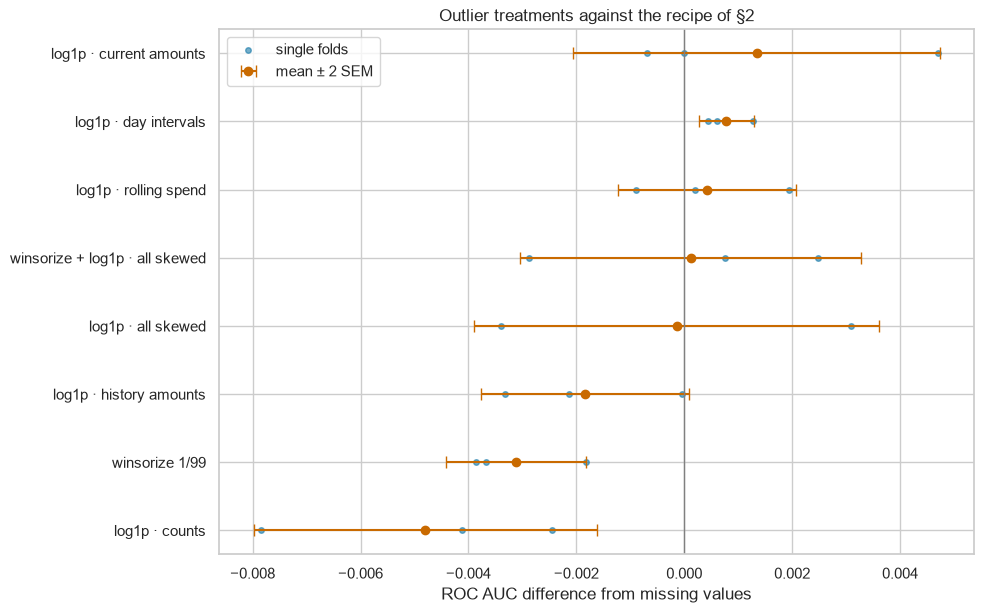

In [23]:
plot_deltas(outlier_names, current, "Outlier treatments against the recipe of §2")

In [24]:
outlier_choice = choose(outlier_names, current)

ADOPTED: outliers · log1p · day intervals (better beyond 2 SEM: ['outliers · log1p · day intervals'])


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ whether winsorize helps or hurts (it caps the biggest customers), why `log1p` on everything at once can be close to zero while single groups are clearly better or worse (gains and losses cancel out), which group passes the rule, and which groups are clearly worse.

## <font color='#E8800A'>3.3 Decision</font>

__Step 19:__ Fix the outlier treatment in the recipe.

In [25]:
if outlier_choice != current:
    RECIPE = {**RECIPE, **TREATMENTS[outlier_choice.split(" · ", 1)[1]]}

current = "after §3 · outliers"
report(current, RECIPE, FRAME, against=V01)
print(f"\nlog1p: {RECIPE['log1p']} | outliers: {RECIPE['outliers']}")

after §3 · outliers: ROC AUC 0.7828 [0.7865, 0.7881, 0.7739]
    vs V01 baseline: dAUC +0.0047 +- 0.0029 (ratio 1.6), better on 3/3 folds -> INSIDE THE NOISE

log1p: ['days_since_previous_purchase', 'prior_mean_gap_days', 'prior_std_gap_days'] | outliers: keep


# <font color='#E8800A'>4. Encoding and scaling</font> <a class="anchor" id="encoding"></a>
[Back to TOC](#toc)

A model reads numbers only, so every categorical level must become a number. Week 4 chooses the **encoder and the scaler together**, crossing every encoder with every scaler. Ordinal, count and target encoding turn a level into a number, and that number is scaled like every other; one-hot indicators stay 0/1. The two choices interact, so they are measured together.

| Encoder | A level becomes | Assumes / risks |
|---|---|---|
| **one-hot** (`drop="first"`) | one 0/1 column per level, the first level dropped as reference | no order between levels; many rare columns when a variable has many levels |
| **ordinal** | an integer per level | an **artificial order**: level 8 is "more" than level 3 |
| **count** | the share of training rows with that level | a level is worth its frequency; two levels with the same frequency become identical |
| **target** | the smoothed repeat rate of that level in training | reads the target, so it is fitted **inside the fold only** |

| Scaler | Does |
|---|---|
| none | raw units |
| standard | mean 0, standard deviation 1 |
| min-max | range [0, 1] |
| robust | median 0, IQR 1: less sensitive to extreme values |

## <font color='#E8800A'>4.1 The categorical columns</font>

__Step 20:__ For each categorical column: number of levels, share of the dominant level, rare levels, and levels that appear in test but never in train.

In [26]:
rows = []
for col in CATEGORICAL:
    counts = X[col].value_counts()
    unseen = X_test[col].notna() & ~X_test[col].isin(counts.index)
    rows.append({"column": col, "levels": counts.size, "top level share": round(counts.iloc[0] / counts.sum(), 3),
                 "levels with < 20 rows": int((counts < 20).sum()),
                 "test rows with an unseen level": int(unseen.sum()),
                 "unseen levels": sorted(X_test.loc[unseen, col].unique())})
pd.DataFrame(rows).set_index("column")

,levels,top level share,levels with < 20 rows,test rows with an unseen level,unseen levels
column,,,,,
payment_type,9,0.728,3,3,"[Maybe Tomorrow Payment 1, Maybe Tomorrow Paym..."
salesperson,9,0.646,3,0,[]
commercial_zone,5,0.968,2,209,"[Decorative Dashboard Zone 1, Decorative Dashb..."
transport_method,80,0.178,46,63,"[Maybe Tomorrow Delivery 54, Maybe Tomorrow De..."
warehouse,2,0.997,0,7,[Final Excel Warehouse 2]
document_series,3,0.423,0,0,[]


__Step 21:__ The same question inside the validation scheme: how many validation rows of each fold carry a level that the fold's training rows never saw? The answer says whether the folds can reproduce the situation of the test.

In [27]:
unseen_by_fold = pd.DataFrame({
    f"fold {k}": {col: int((X[col].iloc[va].notna() & ~X[col].iloc[va].isin(set(X[col].iloc[tr].dropna()))).sum())
                  for col in CATEGORICAL}
    for k, (tr, va) in enumerate(splits, 1)
})
unseen_by_fold["test (vs all train)"] = [int((X_test[c].notna() & ~X_test[c].isin(set(X[c].dropna()))).sum())
                                         for c in CATEGORICAL]
unseen_by_fold

,fold 1,fold 2,fold 3,test (vs all train)
payment_type,6,9,0,3
salesperson,56,0,0,0
commercial_zone,0,0,0,209
transport_method,33,11,23,63
warehouse,0,0,0,7
document_series,0,0,0,0


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ which columns have many rare levels (e.g. `transport_method`), which columns have levels seen only in test (e.g. `commercial_zone`), and whether any fold contains such rows. If a problem exists only in test, the cross-validation cannot measure it.

## <font color='#E8800A'>4.2 What each encoder does with an unseen level</font>

__Step 22:__ Fit each encoder on all train, transform the test rows, and read how every `commercial_zone` level comes out. With `drop="first"`, the reference level is encoded as "all zeros", and `handle_unknown="ignore"` also encodes an unseen level as "all zeros". This is the warning scikit-learn prints for this case, silenced above.

In [28]:
def encoding_of(encoder, column):
    """How each level of `column` in test comes out of `encoder` fitted on all train."""
    recipe = {**RECIPE, "categorical": [column], "encoding": encoder, "scaler": "none", "log1p": [],
              "fill": {"numeric": "median", "categorical": "own level"}}
    fitted = FoldPreprocessor(recipe, selection=None).fit(X, y)
    names = list(fitted.get_feature_names_out())
    width = len(names) - len(recipe["numeric"])            # the categorical block comes first
    encoded = pd.DataFrame(fitted.transform(X_test)[:, :width], columns=names[:width], index=X_test.index)
    encoded.columns = [c.replace(f"{column}_", "") for c in encoded.columns]
    out = encoded.groupby(X_test[column].values).first()
    out.insert(0, "seen in train", out.index.isin(X[column].dropna().unique()))
    out.insert(1, "test rows", X_test[column].value_counts().reindex(out.index).values)
    return out.round(3)


for encoder in ["one-hot", "count", "target"]:
    print(f"--- {encoder}")
    display(encoding_of(encoder, "commercial_zone"))
print("repeat rate per commercial_zone in train:", y.groupby(X["commercial_zone"]).mean().round(3).to_dict())

--- one-hot


,seen in train,test rows,Decorative Dashboard Zone 3,Decorative Dashboard Zone 4,Decorative Dashboard Zone 6,Decorative Dashboard Zone 7
Decorative Dashboard Zone 1,False,189,0.0,0.0,0.0,0.0
Decorative Dashboard Zone 2,True,77,0.0,0.0,0.0,0.0
Decorative Dashboard Zone 3,True,9,1.0,0.0,0.0,0.0
Decorative Dashboard Zone 4,True,691,0.0,1.0,0.0,0.0
Decorative Dashboard Zone 5,False,20,0.0,0.0,0.0,0.0


--- count


,seen in train,test rows,commercial_zone
Decorative Dashboard Zone 1,False,189,0.000
Decorative Dashboard Zone 2,True,77,0.023
Decorative Dashboard Zone 3,True,9,0.009
Decorative Dashboard Zone 4,True,691,0.968
Decorative Dashboard Zone 5,False,20,0.000


--- target


,seen in train,test rows,commercial_zone
Decorative Dashboard Zone 1,False,189,0.560
Decorative Dashboard Zone 2,True,77,0.411
Decorative Dashboard Zone 3,True,9,0.363
Decorative Dashboard Zone 4,True,691,0.565
Decorative Dashboard Zone 5,False,20,0.560


repeat rate per commercial_zone in train: {'Decorative Dashboard Zone 2': 0.411, 'Decorative Dashboard Zone 3': 0.357, 'Decorative Dashboard Zone 4': 0.565, 'Decorative Dashboard Zone 6': 0.0, 'Decorative Dashboard Zone 7': 0.0}


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ with one-hot, which seen level the unseen test levels are encoded like, how many test rows that concerns, and the repeat rate of that level in train; with count and target, what an unseen level becomes.

## <font color='#E8800A'>4.3 The board: 16 combinations</font>

__Step 23:__ Every encoder crossed with every scaler, on the recipe of §3, each against the current recipe (one-hot + standard). Unscaled recipes may print convergence messages: the solver needs more steps when columns have very different scales, which is itself part of what is measured.

In [29]:
ENCODERS = ["one-hot", "ordinal", "count", "target"]
SCALERS = ["none", "standard", "min-max", "robust"]
encoding_names = []
for encoder in ENCODERS:
    for scaler in SCALERS:
        name = f"encoding · {encoder} + {scaler}"
        if (encoder, scaler) == (RECIPE["encoding"], RECIPE["scaler"]):
            board[name], oofs[name], results[name] = board[current], oofs[current], {
                **results[current], **paired_delta(board[current]["ROC AUC"], board[current]["ROC AUC"]),
                "against": current}
            print(f"{name}: the current recipe")
        else:
            report(name, {**RECIPE, "encoding": encoder, "scaler": scaler}, FRAME, against=current)
        encoding_names.append(name)

encoding · one-hot + none: ROC AUC 0.7831 [0.7887, 0.7807, 0.7798]
    vs after §3 · outliers: dAUC +0.0003 +- 0.0040 (ratio 0.1), better on 2/3 folds -> INSIDE THE NOISE
encoding · one-hot + standard: the current recipe
encoding · one-hot + min-max: ROC AUC 0.7785 [0.7786, 0.7856, 0.7713]
    vs after §3 · outliers: dAUC -0.0043 +- 0.0018 (ratio 2.4), better on 0/3 folds -> WORSE
encoding · one-hot + robust: ROC AUC 0.7831 [0.7877, 0.7879, 0.7739]
    vs after §3 · outliers: dAUC +0.0003 +- 0.0004 (ratio 0.8), better on 1/3 folds -> INSIDE THE NOISE
encoding · ordinal + none: ROC AUC 0.7792 [0.7868, 0.7723, 0.7785]
    vs after §3 · outliers: dAUC -0.0036 +- 0.0062 (ratio 0.6), better on 2/3 folds -> INSIDE THE NOISE
encoding · ordinal + standard: ROC AUC 0.7850 [0.7872, 0.7802, 0.7875]
    vs after §3 · outliers: dAUC +0.0022 +- 0.0062 (ratio 0.3), better on 2/3 folds -> INSIDE THE NOISE
encoding · ordinal + min-max: ROC AUC 0.7813 [0.7812, 0.7736, 0.7892]
    vs after §3 · outliers:

In [30]:
grid = pd.DataFrame({e: {s: results[f"encoding · {e} + {s}"]["ROC AUC"] for s in SCALERS} for e in ENCODERS})
grid.style.format("{:.4f}").background_gradient(cmap="Blues", axis=None)

,one-hot,ordinal,count,target
none,0.7831,0.7792,0.7828,0.7809
standard,0.7828,0.7850,0.7887,0.7822
min-max,0.7785,0.7813,0.7851,0.7794
robust,0.7831,0.7851,0.7889,0.7815


In [31]:
show(encoding_names)

,ROC AUC,per fold,dAUC,SEM,ratio,better,verdict,against
encoding · one-hot + none,0.7831,"[0.7887, 0.7807, 0.7798]",+0.0003,0.0040,0.1,2/3,inside the noise,after §3 · outliers
encoding · one-hot + standard,0.7828,"[0.7865, 0.7881, 0.7739]",+0.0000,0.0000,0.0,0/3,identical on every split,after §3 · outliers
encoding · one-hot + min-max,0.7785,"[0.7786, 0.7856, 0.7713]",-0.0043,0.0018,2.4,0/3,worse,after §3 · outliers
encoding · one-hot + robust,0.7831,"[0.7877, 0.7879, 0.7739]",+0.0003,0.0004,0.8,1/3,inside the noise,after §3 · outliers
encoding · ordinal + none,0.7792,"[0.7868, 0.7723, 0.7785]",-0.0036,0.0062,0.6,2/3,inside the noise,after §3 · outliers
encoding · ordinal + standard,0.7850,"[0.7872, 0.7802, 0.7875]",+0.0022,0.0062,0.3,2/3,inside the noise,after §3 · outliers
encoding · ordinal + min-max,0.7813,"[0.7812, 0.7736, 0.7892]",-0.0015,0.0088,0.2,1/3,inside the noise,after §3 · outliers
encoding · ordinal + robust,0.7851,"[0.7878, 0.7805, 0.7872]",+0.0023,0.0061,0.4,2/3,inside the noise,after §3 · outliers
encoding · count + none,0.7828,"[0.7843, 0.7823, 0.7818]",-0.0000,0.0041,0.0,1/3,inside the noise,after §3 · outliers
encoding · count + standard,0.7887,"[0.7868, 0.79, 0.7893]",+0.0059,0.0048,1.2,3/3,inside the noise,after §3 · outliers


In [32]:
encoding_by_rule = choose(encoding_names, current)

KEPT: after §3 · outliers (no candidate is better beyond 2 SEM)


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ which combinations have the highest mean and on how many folds they win, whether any passes 2 SEM, which scaler is worst with one-hot, why ordinal is unstable across folds, and whether standard and robust differ.

__Step 24:__ Diagnostic only, not a candidate: remove one categorical column at a time from the current recipe, to see which one drives the fold-by-fold pattern. Removing columns is a feature-selection decision and belongs to `05_features`.

In [33]:
for col in CATEGORICAL:
    report(f"diagnostic · without {col}", {**RECIPE, "categorical": [c for c in CATEGORICAL if c != col]},
           FRAME, against=current)

diagnostic · without payment_type: ROC AUC 0.7840 [0.7843, 0.7903, 0.7774]
    vs after §3 · outliers: dAUC +0.0012 +- 0.0017 (ratio 0.7), better on 2/3 folds -> INSIDE THE NOISE
diagnostic · without salesperson: ROC AUC 0.7806 [0.7848, 0.7841, 0.7728]
    vs after §3 · outliers: dAUC -0.0022 +- 0.0009 (ratio 2.5), better on 0/3 folds -> WORSE
diagnostic · without commercial_zone: ROC AUC 0.7824 [0.788, 0.7865, 0.7727]
    vs after §3 · outliers: dAUC -0.0004 +- 0.0010 (ratio 0.4), better on 1/3 folds -> INSIDE THE NOISE
diagnostic · without transport_method: ROC AUC 0.7875 [0.7901, 0.7864, 0.786]
    vs after §3 · outliers: dAUC +0.0047 +- 0.0040 (ratio 1.2), better on 2/3 folds -> INSIDE THE NOISE
diagnostic · without warehouse: ROC AUC 0.7815 [0.7862, 0.786, 0.7722]
    vs after §3 · outliers: dAUC -0.0014 +- 0.0005 (ratio 2.6), better on 0/3 folds -> WORSE
diagnostic · without document_series: ROC AUC 0.7816 [0.7883, 0.7847, 0.7719]
    vs after §3 · outliers: dAUC -0.0012 +- 0.001

**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ which column, once removed, changes the score most and on which fold; how many levels that column has (§4.1).

## <font color='#E8800A'>4.4 Decision</font>

The cross-validation cannot measure the problem shown in §4.2: no fold contains a `commercial_zone` level unseen in its training rows, while the test does. Week 5: a validation estimate is trustworthy only where the validation and the test ask the same question. So the encoder is decided in two steps:
1. **Read the board:** if no encoder is better beyond 2 SEM, the board does not separate them.
2. **Among encoders the board cannot separate,** choose the one that treats a level never seen in training correctly. Count encoding turns it into 0, "never seen". One-hot with `drop="first"` turns it into the reference level, a real level with its own repeat rate.

__Step 25:__ Apply the two steps.

In [34]:
CANDIDATE = "encoding · count + standard"
check = results[CANDIDATE]
print(f"rule on the board: {encoding_by_rule}")
print(f"{CANDIDATE}: dAUC {check['dAUC']:+.4f} +- {check['SEM']:.4f} (ratio {check['ratio']:.1f}),"
      f" better on {check['better']} folds -> {check['verdict']}")

if encoding_by_rule != current:
    encoding_choice = encoding_by_rule                       # the board decides
elif check["verdict"] != "worse":
    encoding_choice = CANDIDATE                              # board cannot separate: unseen levels decide
else:
    encoding_choice = current                                # count is measurably worse: keep one-hot
print(f"CHOSEN: {encoding_choice}")

rule on the board: after §3 · outliers
encoding · count + standard: dAUC +0.0059 +- 0.0048 (ratio 1.2), better on 3/3 folds -> inside the noise
CHOSEN: encoding · count + standard


In [35]:
encoder, scaler = encoding_choice.split(" · ", 1)[1].split(" + ")
RECIPE = {**RECIPE, "encoding": encoder, "scaler": scaler, "drop": "first" if encoder == "one-hot" else None}

current = "after §4 · encoding and scaling"
report(current, RECIPE, FRAME, against=V01)
print(f"\nencoding: {RECIPE['encoding']} | scaler: {RECIPE['scaler']}")

after §4 · encoding and scaling: ROC AUC 0.7887 [0.7868, 0.79, 0.7893]
    vs V01 baseline: dAUC +0.0106 +- 0.0029 (ratio 3.7), better on 3/3 folds -> BETTER

encoding: count | scaler: standard


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ the board verdict of count + standard (ratio and folds won), which branch of the rule decided, and the recipe after this block.

# <font color='#E8800A'>5. The final recipe</font> <a class="anchor" id="final"></a>
[Back to TOC](#toc)

__Step 26:__ The recipe the three blocks chose, against the starting recipe and against the V01 pipeline.

In [36]:
FINAL, FINAL_FRAME = RECIPE, FRAME
for key in ["fill", "log1p", "outliers", "encoding", "drop", "scaler", "strategy"]:
    print(f"  {key:9s} {FINAL[key]}")
print(f"  columns   {len(FINAL['numeric'])} numeric, {len(FINAL['categorical'])} categorical\n")

for against in ["start (course format)", V01]:
    r = paired_delta(board[current]["ROC AUC"], board[against]["ROC AUC"])
    print(f"final vs {against}: dAUC {r['dAUC']:+.4f} +- {r['SEM']:.4f} (ratio {r['ratio']:.1f}),"
          f" better on {r['better']} folds -> {r['verdict'].upper()}")

  fill      {'numeric': 'iterative', 'standardised': True, 'random_state': 42, 'categorical': 'own level'}
  log1p     ['days_since_previous_purchase', 'prior_mean_gap_days', 'prior_std_gap_days']
  outliers  keep
  encoding  count
  drop      None
  scaler    standard
  strategy  None
  columns   28 numeric, 6 categorical

final vs start (course format): dAUC +0.0087 +- 0.0050 (ratio 1.7), better on 3/3 folds -> INSIDE THE NOISE
final vs V01 baseline: dAUC +0.0106 +- 0.0029 (ratio 3.7), better on 3/3 folds -> BETTER


__Step 27:__ The honest F1, as in `validation_ludovico` and the V01 submission: the threshold is chosen on the earlier folds and the F1 is scored on the last fold, the one closest to the test. This is the number that goes next to a Kaggle score.

In [37]:
def honest_f1(name):
    """F1 on the last fold at the threshold that maximises F1 on the earlier folds."""
    oof = oofs[name]
    early = np.concatenate([va for _, va in splits[:-1]])
    last = splits[-1][1]
    threshold, _ = best_threshold(y.iloc[early], oof.iloc[early])
    return f1_score(y.iloc[last], oof.iloc[last] >= threshold), threshold


last = splits[-1][1]
floor = f1_score(y.iloc[last], np.ones(len(last)))
pd.DataFrame({name: dict(zip(["honest F1", "threshold (earlier folds)"], honest_f1(name)),
                         **{"F1 always 1 (last fold)": floor})
              for name in [V01, "start (course format)", current]}).T.style.format("{:.3f}")

,honest F1,threshold (earlier folds),F1 always 1 (last fold)
V01 baseline,0.771,0.370,0.754
start (course format),0.771,0.380,0.754
after §4 · encoding and scaling,0.787,0.330,0.754


__Step 28:__ The recipe was chosen through a logistic regression. Does it hold for other model families? An untuned gradient boosting (trees: insensitive to scaling and `log1p`) and an untuned KNN (distances: very sensitive to scaling), each with the starting and the final recipe.

In [38]:
OTHER_MODELS = {"gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                "KNN (k=25)": KNeighborsClassifier(n_neighbors=25)}
for model_name, model in OTHER_MODELS.items():
    report(f"{model_name} · start", START, X, model=clone(model))
    report(f"{model_name} · final", FINAL, FINAL_FRAME, against=f"{model_name} · start", model=clone(model))

gradient boosting · start: ROC AUC 0.7596 [0.7553, 0.7429, 0.7806]
gradient boosting · final: ROC AUC 0.7663 [0.7654, 0.7469, 0.7867]
    vs gradient boosting · start: dAUC +0.0067 +- 0.0018 (ratio 3.8), better on 3/3 folds -> BETTER
KNN (k=25) · start: ROC AUC 0.7628 [0.762, 0.7522, 0.7742]
KNN (k=25) · final: ROC AUC 0.7396 [0.7159, 0.7542, 0.7488]
    vs KNN (k=25) · start: dAUC -0.0231 +- 0.0139 (ratio 1.7), better on 1/3 folds -> INSIDE THE NOISE


**Reading** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_What to check:_ the gain of the final recipe over the start and over V01 in ROC AUC, whether the honest F1 moves (preprocessing may improve the ranking without moving F1), and whether the recipe is safe for trees and KNN (inside the noise or better).

# <font color='#E8800A'>6. The decision log</font> <a class="anchor" id="log"></a>
[Back to TOC](#toc)

__Step 29:__ Record each decision in a `CleaningLog`, as Weeks 3 and 4 do: the sentence a reader needs, and a `carries` structure a later notebook can apply. The log stores **rules, not fitted values**: medians, encoder levels and scaler limits are refitted on whatever training rows the next notebook uses (Week 4: *carry the strategy, not the columns*).

In [39]:
def evidence(names, reference):
    """One short line per candidate: paired dAUC, SEM and verdict against `reference`."""
    return "; ".join(f"{n.split(' · ', 1)[1]}: {results[n]['dAUC']:+.4f} +- {results[n]['SEM']:.4f} ({results[n]['verdict']})"
                     for n in names if n != reference and results[n].get("against") == reference)


log = CleaningLog("everything_and_then_some")
log.record(
    "customer_id, purchase_date, random_noise",
    "kept out of the model inputs (identifier, raw date, decoy column)",
    "as in validation_ludovico; their final treatment is decided in 05_features",
    len(X), carries={"dropped": FINAL["dropped"]},
)
log.record(
    f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical columns",
    f"missing values: {fill_choice.split(' · ', 1)[1]}, fitted inside each training fold",
    f"Week 3 fill plans against {FILL_REFERENCE}: " + evidence(fill_names, reference),
    int(X.isna().any(axis=1).sum()),
    carries={"fill": FINAL["fill"], "numeric": NUMERIC, "categorical": CATEGORICAL},
)
log.record(
    ", ".join(FLAGS),
    "added as constructed 0/1 columns" if flags_added else "tested and not added",
    f"structural gaps depend on prior_purchase_count; {results[flags_name]['dAUC']:+.4f}"
    f" +- {results[flags_name]['SEM']:.4f} ({results[flags_name]['verdict']})",
    int(add_history_flags(X)[FLAGS].any(axis=1).sum()),
    carries={"features": FLAGS, "rule": "prior_purchase_count == 0 / == 1 / == 2", "adopted": bool(flags_added)},
)
log.record(
    ", ".join(FINAL["log1p"]) if FINAL["log1p"] else "numeric columns",
    f"outliers: no row deleted ({FINAL['outliers']}); log1p on {len(FINAL['log1p'])} columns",
    f"the 1.5*IQR rule flags {flagged.mean():.0%} of train rows (repeat rate {y[flagged].mean():.2f}"
    f" vs {y[~flagged].mean():.2f}), so it only screens; treatments: "
    + evidence(outlier_names, "after §2 · missing values"),
    int(flagged.sum()),
    carries={"transform": "log1p" if FINAL["log1p"] else "none", "columns": FINAL["log1p"],
             "outliers": FINAL["outliers"], "rule_tested": "IQR k=1.5 (screening only)"},
)
log.record(
    f"all {len(FINAL['numeric']) + len(FINAL['categorical'])} feature columns",
    f"{FINAL['encoding']} encoding + {FINAL['scaler']} scaling, fitted inside each training fold",
    f"16 encoder x scaler combinations (Week 4); board rule: {encoding_by_rule.split(' · ', 1)[1]};"
    f" chosen: {encoding_choice.split(' · ', 1)[1]}, because one-hot with drop='first' encodes levels"
    " never seen in training (209 commercial_zone test rows) as the reference level",
    len(X),
    carries={"encoding": FINAL["encoding"], "scaler": FINAL["scaler"], "drop": FINAL["drop"],
             "numeric": FINAL["numeric"], "categorical": FINAL["categorical"], "dropped": FINAL["dropped"],
             "candidates": {n.split(" · ", 1)[1]: round(float(results[n]["ROC AUC"]), 4) for n in encoding_names}},
)
log.record("encoded columns", "no feature selection yet", "decided in 05_features", 0,
           carries={"strategy": None})

log.to_json(LOG_PATH)
pd.DataFrame(log.records())

,column,action,reason,rows_affected
0,"customer_id, purchase_date, random_noise","kept out of the model inputs (identifier, raw ...",as in validation_ludovico; their final treatme...,6469
1,28 numeric + 6 categorical columns,"missing values: iterative / own level, fitted ...",Week 3 fill plans against median / own level: ...,2157
2,"no_prior_purchase, one_prior_purchase, two_pri...",tested and not added,structural gaps depend on prior_purchase_count...,1413
3,"days_since_previous_purchase, prior_mean_gap_d...",outliers: no row deleted (keep); log1p on 3 co...,the 1.5*IQR rule flags 66% of train rows (repe...,4259
4,all 34 feature columns,"count encoding + standard scaling, fitted insi...",16 encoder x scaler combinations (Week 4); boa...,6469
5,encoded columns,no feature selection yet,decided in 05_features,0


__Step 30:__ Check that the log alone rebuilds the final recipe.

In [40]:
def recipe_from_log(path):
    """Rebuild a FoldPreprocessor recipe from a log written above."""
    carries = [step.carries for step in CleaningLog.load(path).steps if step.carries]
    pick = lambda *keys: next(c for c in carries if all(k in c for k in keys))
    fill, transform = pick("fill", "numeric", "categorical"), pick("transform", "columns")
    representation, strategy = pick("encoding", "scaler"), pick("strategy")
    return {"numeric": representation["numeric"], "categorical": representation["categorical"],
            "dropped": representation["dropped"], "fill": fill["fill"],
            "log1p": transform["columns"] if transform["transform"] == "log1p" else [],
            "outliers": transform["outliers"], "encoding": representation["encoding"],
            "drop": representation["drop"], "scaler": representation["scaler"],
            "strategy": strategy["strategy"]}


assert recipe_from_log(LOG_PATH) == FINAL, "the log does not rebuild the final recipe"
print(f"{LOG_PATH.relative_to(PROJECT_ROOT)} rebuilds the final recipe exactly")

docs\preprocessing_log.json rebuilds the final recipe exactly


# <font color='#E8800A'>7. Summary</font> <a class="anchor" id="summary"></a>
[Back to TOC](#toc)

__Step 31:__ Every decision of the notebook, with its evidence, read from the board.

In [41]:
def line(name, against):
    r = paired_delta(board[name]["ROC AUC"], board[against]["ROC AUC"])
    return f"{r['dAUC']:+.4f} +- {r['SEM']:.4f}, {r['better']} folds ({r['verdict']})"


pd.DataFrame([
    {"block": "missing values", "decision": fill_choice.split(" · ", 1)[1],
     "evidence": line(fill_choice, reference) if fill_choice != reference else "reference kept"},
    {"block": "history flags", "decision": "added" if flags_added else "not added",
     "evidence": line(flags_name, fill_choice)},
    {"block": "outliers", "decision": f"no row deleted; log1p on {FINAL['log1p'] or 'nothing'}",
     "evidence": line(outlier_choice, "after §2 · missing values")
     if outlier_choice != "after §2 · missing values" else "no treatment kept"},
    {"block": "encoding + scaling", "decision": f"{FINAL['encoding']} + {FINAL['scaler']}",
     "evidence": line(encoding_choice, "after §3 · outliers") if encoding_choice != "after §3 · outliers"
     else "current kept"},
    {"block": "final recipe vs V01", "decision": "all blocks together", "evidence": line(current, V01)},
]).set_index("block")

,decision,evidence
block,,
missing values,iterative / own level,"+0.0010 +- 0.0004, 3/3 folds (better)"
history flags,not added,"-0.0002 +- 0.0008, 1/3 folds (inside the noise)"
outliers,no row deleted; log1p on ['days_since_previous...,"+0.0008 +- 0.0003, 3/3 folds (better)"
encoding + scaling,count + standard,"+0.0059 +- 0.0048, 3/3 folds (inside the noise)"
final recipe vs V01,all blocks together,"+0.0106 +- 0.0029, 3/3 folds (better)"


**Conclusions** <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>

_To write from the table above and §5: what each block decided and why, how large the total gain is, whether the honest F1 moved, and what is left for `05_features` (e.g. how `transport_method` enters the model, zero-inflated columns such as `discount_global` and `total_shipping`)._

### Lines for `docs/decisions.md` <font color='#C96A00'>[TO BE CONFIRMED AFTER RUNNING]</font>
| Decision | Alternatives considered | Evidence |
|---|---|---|
| Fill: … | median, mean, zero, mode, proportional, KNN, iterative | `preprocessing_nico` §2 |
| No missing-value flags | 3 flags for 0 / 1 / 2 prior purchases | §2.4 |
| No row deleted; IQR only screens; log1p on … | winsorize 1/99, log1p on all or by group | §3 |
| Encoding … + scaling … | 16 encoder × scaler combinations | §4 |